# 03. Wskaźnik Wachty na naszych nagraniach z etykietami protokołu

Stosujemy do czterech nagrań z BrainAccess dokładnie ten schemat, który ma działać w demo: **kalibracja na początku, potem z-score każdego okna 2 s względem własnej bazy** i prosta reguła stanu. W poprzedniej wersji tego notebooka nie było etykiet, więc porównywaliśmy wskaźnik z epizodami alfy wykrytymi z tego samego sygnału (wniosek kołowy). Teraz mamy bloki protokołu z `data/recordings/*-raw_annotations.csv` i liczymy trafność naprawdę.

Co oznaczają bloki (doprecyzowanie zespołu, dokładniejsze niż README nagrań):

| Etykieta | Co się działo |
|---|---|
| `neutral` | swobodna rozmowa i normalne funkcjonowanie (mówienie, ruch). **To nie jest spokojny spoczynek z otwartymi oczami**, więc jest w nim aktywność mięśni mowy i ruch |
| `eyes_closed` | oczy zamknięte |
| `reading` | czytanie tekstu |
| `math` | liczenie w pamięci |
| `control` | sekwencja: otwieranie i zamykanie oczu, zaciskanie szczęki, kręcenie głową. **Brak znaczników wewnątrz bloku** |

Odcinki bez etykiety: rudy 360–420 s, wojtek 425–430 s.

Pytania:

1. Czy wskaźnik czujności (z-score alfy potylicznej O1/O2 względem kalibracji z 60 czystych okien na początku `neutral`) wykrywa `eyes_closed`? Czułość, fałszywe alarmy poza blokiem, AUC, opóźnienie. Która cecha jest lepsza: moc alfy czy wyrazistość alfy?
2. Czym różnią się `reading` i `math` od `neutral` (theta czołowa, alfa ciemieniowa, alfa potyliczna, beta/(alfa+theta), (theta+alfa)/beta)? Tylko obserwacja, n = 4.
3. Jak w naszych 8 kanałach wygląda blok `control` (mrugnięcia i zamykanie oczu, zaciskanie szczęki, ruch głowy), czy łapie go próg 300 µV i czy robi fałszywe flagi „senny”?
4. Na ile epizody alfy z notebooka 01 (wykryte z samego sygnału) pokrywają się z prawdziwym `eyes_closed`?
5. Jak wynik zależy od wyboru kalibracji i od odrzucania artefaktów?

Mówimy o **zmęczeniu i czujności**. Zamknięte oczy to tu zastępczy model spadku czujności (mikrosnu), a nie senność zmierzona na zmęczonych osobach.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300          # drop 2 s windows whose peak-to-peak exceeds this (any channel)
PERSON_COLORS = {"adi": "tab:blue", "filip": "tab:orange", "rudy": "tab:green", "wojtek": "tab:red"}


def find_recordings():
    """Locate data/recordings (repo checkout, Colab upload, or fresh clone)."""
    for p in [Path("../recordings"), Path("data/recordings"), Path("recordings"), Path("/content/recordings")]:
        if list(p.glob("*raw.fif")):
            return p
    import subprocess
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/wskalecki/Heroes_of_the_brain_AI_All_IN.git", "/content/repo"],
        capture_output=True,
    )
    p = Path("/content/repo/data/recordings")
    if list(p.glob("*raw.fif")):
        return p
    raise FileNotFoundError(
        "Nie znaleziono plików *raw.fif. Wgraj je do /content/recordings (panel plików w Colabie) "
        "albo sklonuj repo (jeśli jest prywatne, trzeba tokenu)."
    )


def load_recordings(rec_dir):
    out = {}
    for f in sorted(rec_dir.glob("*raw.fif")):
        out[f.name.split("task-")[1].split("_")[0]] = mne.io.read_raw_fif(f, preload=True)
    return out


def accel_jerk(raw):
    """Smoothed magnitude of accelerometer change (a movement proxy), one value per sample."""
    a = raw.copy().pick(["Accel_x", "Accel_y", "Accel_z"]).get_data()
    j = np.sqrt((np.diff(a, axis=1) ** 2).sum(0))
    j = np.r_[j[0], j]
    return pd.Series(j).rolling(FS, center=True, min_periods=1).mean().values


def find_end_trim(raw, factor=3.0):
    """Time (s) from which movement stays high until the end (headset being taken off)."""
    j = accel_jerk(raw)
    low = np.where(j < factor * np.median(j))[0]
    return raw.times[low[-1]] if len(low) else raw.times[-1]


def clean_windows(raw8, hp_only=False):
    """Epoch a raw (8 EEG channels) into 2 s windows with 1 s step."""
    return mne.make_fixed_length_epochs(raw8, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)

from scipy.signal import welch
from sklearn.metrics import roc_auc_score

BANDS = {"theta": (4, 7), "alpha": (8, 12), "beta": (13, 30)}
CAL_WINDOWS = 60        # first 60 clean windows (~60 s) = calibration, like in the demo
SMOOTH = 5              # median over the last 5 windows (causal, as in a live system)
Z_SLEEPY = 2.0          # z above this -> window flagged "sleepy"
MIN_RUN = 3             # flagged for >= 3 consecutive windows (3 s) -> alarm "spadek czujności"
GUARD_S = 5             # first 5 s after eyes_closed ends are not counted as false alarms (smoothing lag)
BLOCKS = ["neutral", "eyes_closed", "reading", "math", "control"]
BLOCK_COLORS = {"neutral": "#dddddd", "eyes_closed": "#f4c542", "reading": "#9ecae1",
                "math": "#c39bd3", "control": "#f1948a"}

## 1. Nagrania i etykiety

In [2]:
REC = find_recordings()
raws = load_recordings(REC)
labels = {}
for f in sorted(REC.glob("*raw_annotations.csv")):
    labels[f.name.split("task-")[1].split("_")[0]] = pd.read_csv(f)
ep_csv = next(p for p in [Path("alpha-episodes.csv"), REC.parent / "analysis" / "alpha-episodes.csv"] if p.exists())
episodes = pd.read_csv(ep_csv)

pd.DataFrame({n: {b: f"{L.onset[i]:.0f}–{L.onset[i] + L.duration[i]:.0f}" for i, b in enumerate(L.description)}
              | {"koniec nagrania": f"{raws[n].times[-1]:.0f}"} for n, L in labels.items()}).T

,neutral,eyes_closed,reading,math,control,koniec nagrania
adi,0–300,300–360,360–435,435–505,505–548,548
filip,0–600,600–660,660–740,740–840,840–881,881
rudy,0–300,300–360,420–450,450–524,524–544,544
wojtek,0–300,300–363,363–425,430–484,484–509,509


### Uwaga o obcinaniu końcówki

W poprzednich notebookach obcinaliśmy końcówkę nagrania, w której akcelerometr pokazuje ruch aż do końca (zdejmowanie czapki, funkcja `find_end_trim`). Blok `control` leży na samym końcu, więc sprawdzamy, ile by z niego zjadło takie obcięcie.

In [3]:
rows = []
for n, r in raws.items():
    L = labels[n]; c = L[L.description == "control"].iloc[0]
    trim = find_end_trim(r)
    rows.append(dict(osoba=n, control=f"{c.onset:.0f}–{c.onset + c.duration:.0f} s", obciecie_od=round(trim, 1),
                     zjedzone_z_control_s=round(max(0, c.onset + c.duration - trim), 1)))
pd.DataFrame(rows).set_index("osoba")

,control,obciecie_od,zjedzone_z_control_s
osoba,,,
adi,505–548 s,533.3,14.8
filip,840–881 s,880.7,0.0
rudy,524–544 s,534.4,9.3
wojtek,484–509 s,509.5,0.0


`find_end_trim` ucięłoby 14,8 s z bloku `control` u adi i 9,3 s u rudego, a u filipa i wojtka nie ucina nic, choć w ich końcówce też jest silny ruch (wykresy w sekcji 5). Dlatego **w tym notebooku niczego nie obcinamy**: analizujemy cały oznaczony czas, a przed śmieciami chroni odrzucanie okien powyżej 300 µV. Bez znaczników wewnątrz `control` nie da się oddzielić kręcenia głową od ewentualnego zdejmowania czapki na samym końcu.

## 2. Tabela okien

Dla każdego okna 2 s (krok 1 s) liczymy:

- `alpha_occ`: log10 mocy 8–12 Hz na O1/O2 (cecha wskaźnika v0),
- `prom_occ`: wyrazistość alfy na O1/O2, log10 stosunku mocy 8–12 Hz do średniej geometrycznej 5–7 i 14–16 Hz (jak w notebooku 01),
- `theta_front` (F3/F4, 4–7 Hz), `alpha_par` (P3/P4, 8–12 Hz), `engagement` = beta/(alfa+theta) i `fatigue` = (theta+alfa)/beta, obie średnio z 8 kanałów i w log10,
- `emg`: log10 mocy 60–95 Hz (sygnał po samym filtrze 1 Hz, średnia z kanałów), czyli napięcie mięśni,
- `lf_front`, `lf_occ`: log10 mocy 1–3 Hz na F3/F4 i na O1/O2 (wolne fale: mrugnięcia, ruch oczu, ruch elektrod),
- `ptp`: maksymalna amplituda szczyt-szczyt (1–40 Hz) po kanałach, `jerk`: ruch z akcelerometru,
- `block`: etykieta, jeśli okno w całości leży w bloku; `granica`, jeśli przecina granicę bloków; `brak`, jeśli leży w przerwie bez etykiety.

In [4]:
def band_power(f, p, lo, hi):
    m = (f >= lo) & (f <= hi)
    return p[..., m].sum(-1) * (f[1] - f[0])


def window_table(raw, L):
    r8 = raw.copy().pick(OUR_CH)
    ep = clean_windows(r8.copy().filter(1, 40, verbose=False))
    eh = clean_windows(r8.copy().filter(1, None, verbose=False))
    X = ep.get_data()
    starts = ep.events[:, 0]
    f, p = welch(X, FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p * 1e12                                                    # µV²/Hz
    pw = {b: band_power(f, p, lo, hi) for b, (lo, hi) in BANDS.items()}   # (win, ch)
    po = p[:, [6, 7]].mean(1)                                       # O1/O2 PSD
    mb = lambda lo, hi: po[:, (f >= lo) & (f <= hi)].mean(1)
    fh, ph = welch(eh.get_data(), FS, nperseg=int(WIN_S * FS), axis=-1)
    ph = ph * 1e12
    jerk = accel_jerk(raw)
    ta = pw["theta"].mean(1) + pw["alpha"].mean(1)
    T = pd.DataFrame({
        "t": starts / FS,
        "alpha_occ": np.log10(pw["alpha"][:, [6, 7]].mean(1)),
        "prom_occ": np.log10(mb(8, 12) / np.sqrt(mb(5, 7) * mb(14, 16))),
        "theta_front": np.log10(pw["theta"][:, [0, 1]].mean(1)),
        "alpha_par": np.log10(pw["alpha"][:, [4, 5]].mean(1)),
        "engagement": np.log10(pw["beta"].mean(1) / ta),
        "fatigue": np.log10(ta / pw["beta"].mean(1)),
        "emg": np.log10(ph[:, :, (fh >= 60) & (fh <= 95)].mean(-1).mean(1)),
        "lf_front": np.log10(band_power(fh, ph[:, [0, 1]], 1, 3).mean(1)),
        "lf_occ": np.log10(band_power(fh, ph[:, [6, 7]], 1, 3).mean(1)),
        "ptp": np.ptp(X, axis=-1).max(1) * 1e6,
        "jerk": [jerk[s:s + int(WIN_S * FS)].mean() for s in starts],
    })
    T["bad"] = T.ptp > REJECT_UV
    T["t_end"] = T.t + WIN_S                                        # decision time of the window
    T["block"] = "brak"
    for _, a in L.iterrows():
        a0, a1 = a.onset, a.onset + a.duration
        inside = (T.t >= a0 - 1e-6) & (T.t_end <= a1 + 1e-6)
        cross = (T.t < a1) & (T.t_end > a0) & ~inside
        T.loc[inside, "block"] = a.description
        T.loc[cross, "block"] = "granica"
    return T


tables = {n: window_table(r, labels[n]) for n, r in raws.items()}
summary = pd.DataFrame({n: T.groupby("block").bad.agg(lambda s: f"{len(s)} ({100 * s.mean():.0f}% odrz.)")
                        for n, T in tables.items()}).T
summary[["neutral", "eyes_closed", "reading", "math", "control", "granica", "brak"]].fillna("–")

block,neutral,eyes_closed,reading,math,control,granica,brak
adi,299 (20% odrz.),59 (0% odrz.),74 (26% odrz.),69 (25% odrz.),42 (55% odrz.),4 (25% odrz.),–
filip,599 (5% odrz.),59 (0% odrz.),79 (0% odrz.),99 (0% odrz.),39 (36% odrz.),4 (0% odrz.),–
rudy,299 (25% odrz.),59 (0% odrz.),29 (10% odrz.),73 (36% odrz.),18 (67% odrz.),5 (40% odrz.),59 (8% odrz.)
wojtek,299 (16% odrz.),62 (15% odrz.),61 (0% odrz.),53 (0% odrz.),24 (83% odrz.),5 (40% odrz.),4 (0% odrz.)


## 3. Wykrywanie `eyes_closed`

Reguła, tak jak w pipeline demo:

1. Kalibracja: średnia i odchylenie cechy z **pierwszych 60 czystych okien nagrania** (początek `neutral`, czyli rozmowa).
2. Z-score każdego czystego okna; okna odrzucone nie dostają wartości (system mówi wtedy „brak sygnału”, a nie „czujny”).
3. Wygładzenie: mediana z ostatnich 5 okien (przyczynowo, czyli bez zaglądania w przyszłość, tak jak na żywo).
4. Okno „senne”: wygładzony z-score > 2. **Alarm** („spadek czujności”): co najmniej 3 senne okna z rzędu.

Miary:

- **czułość**: odsetek czystych okien w `eyes_closed` oznaczonych jako senne,
- **fałszywe flagi**: odsetek czystych okien w blokach z na pewno otwartymi oczami (`neutral`, `reading`, `math`) oznaczonych jako senne, łącznie i w podziale na bloki; pierwsze 5 s po końcu `eyes_closed` pomijamy (opóźnienie wygładzania),
- **fałszywe alarmy na minutę**: liczba startów alarmu w tych blokach na minutę ich czystego czasu,
- **`control` osobno**: zawiera celowe zamykanie oczu, więc flaga „senny” może tam być prawdziwa; podajemy ją osobno, razem z liczbą czystych okien,
- **AUC**: `eyes_closed` kontra wszystkie inne okna z etykietą (bez okien na granicy i bez przerw), na surowym z-score okna i na wygładzonym,
- **opóźnienie**: czas od początku bloku do pierwszego alarmu (koniec okna, w którym alarm się włącza).

In [5]:
FEATURES = {"alpha_occ": "moc alfy O1/O2", "prom_occ": "wyrazistość alfy O1/O2"}


def calibrate(T, col, method="cal60", reject=True):
    ok = ~T.bad if reject else pd.Series(True, index=T.index)
    v = T.loc[ok, col]
    if method == "cal60":                       # first 60 clean windows = start of neutral
        base = v.iloc[:CAL_WINDOWS]; return base.mean(), base.std()
    if method == "cal60_late":                  # last 60 clean windows of neutral, right before eyes_closed
        base = T.loc[ok & (T.block == "neutral"), col].iloc[-CAL_WINDOWS:]; return base.mean(), base.std()
    if method == "full":                        # whole session (sees eyes_closed too: optimistic)
        return v.median(), (v - v.median()).abs().median() * 1.4826
    raise ValueError(method)


def detect(T, col, method="cal60", reject=True):
    T = T.copy()
    ok = ~T.bad if reject else pd.Series(True, index=T.index)
    mu, sd = calibrate(T, col, method, reject)
    T["z"] = ((T[col] - mu) / sd).where(ok)
    T["zs"] = T.z.rolling(SMOOTH, min_periods=1).median().where(ok)
    T["flag"] = (T.zs > Z_SLEEPY) & ok
    run = T.flag.groupby((~T.flag).cumsum()).cumsum()            # length of current flagged run
    T["alarm"] = run >= MIN_RUN
    T["alarm_on"] = run == MIN_RUN                               # moment the alarm switches on
    T["ok"] = ok
    return T


def ec_window(L):
    a = L[L.description == "eyes_closed"].iloc[0]
    return a.onset, a.onset + a.duration


def scores(T, L):
    e0, e1 = ec_window(L)
    lab = T.block.isin(BLOCKS) & T.ok
    pos = lab & (T.block == "eyes_closed")
    guard = (T.t_end > e1) & (T.t_end <= e1 + GUARD_S)
    # false alarms: only blocks where the eyes are known to be open (control contains deliberate eye closing)
    neg = lab & T.block.isin(["neutral", "reading", "math"]) & ~guard
    first = T[T.alarm_on & (T.t_end >= e0) & (T.t_end <= e1 + GUARD_S)]
    out = {"czułość [%]": 100 * T.flag[pos].mean(),
           "alarm w bloku": len(first) > 0,
           "opóźnienie [s]": first.t_end.iloc[0] - e0 if len(first) else np.nan,
           "fałszywe flagi [% czystego czasu]": 100 * T.flag[neg].mean(),
           "fałszywe alarmy [liczba]": int(T.alarm_on[neg].sum()),
           "fałszywe alarmy [/min]": T.alarm_on[neg].sum() / (neg.sum() / 60)}
    m = pos | (lab & (T.block != "eyes_closed"))
    out["AUC okno"] = roc_auc_score(pos[m], T.z[m])
    out["AUC wygładzone"] = roc_auc_score(pos[m], T.zs[m])
    for b in ["neutral", "reading", "math"]:
        mb = neg & (T.block == b)
        out[f"flagi w {b} [%]"] = 100 * T.flag[mb].mean() if mb.any() else np.nan
    mc = lab & (T.block == "control")
    out["control: czyste okna"] = int(mc.sum())
    out["control: flagi [%]"] = 100 * T.flag[mc].mean() if mc.any() else np.nan
    return out


D = {col: {n: detect(T, col) for n, T in tables.items()} for col in FEATURES}
res = pd.DataFrame([dict(cecha=FEATURES[col], osoba=n, **scores(D[col][n], labels[n]))
                    for col in FEATURES for n in tables])
res.round(2).set_index(["cecha", "osoba"])

czułość [%]  alarm w bloku  opóźnienie [s]  \
cecha                  osoba                                                
moc alfy O1/O2         adi            3.39          False             NaN   
                       filip         93.22           True             8.0   
                       rudy          20.34           True            11.0   
                       wojtek        18.87           True            45.0   
wyrazistość alfy O1/O2 adi           49.15           True            12.0   
                       filip         81.36           True             9.0   
                       rudy          89.83           True             7.0   
                       wojtek        71.70           True            13.0   

                               fałszywe flagi [% czystego czasu]  \
cecha                  osoba                                       
moc alfy O1/O2         adi                                  0.29   
                       filip                                0.00   
                       rudy                                 0.00   
                       wojtek                               2.50   
wyrazistość alfy O1/O2 adi                                  0.00   
                       filip                                0.00   
                       rudy                                 0.00   
                       wojtek                               3.33   

                               fałszywe alarmy [liczba]  \
cecha                  osoba                              
moc alfy O1/O2         adi                            0   
                       filip                          0   
                       rudy                           0   
                       wojtek                         2   
wyrazistość alfy O1/O2 adi                            0   
                       filip                          0   
                       rudy                           0   
                       wojtek                         3   

                               fałszywe alarmy [/min]  AUC okno  \
cecha                  osoba                                      
moc alfy O1/O2         adi                       0.00      0.64   
                       filip                     0.00      0.98   
                       rudy                      0.00      0.91   
                       wojtek                    0.33      0.65   
wyrazistość alfy O1/O2 adi                       0.00      0.86   
                       filip                     0.00      0.97   
                       rudy                      0.00      0.97   
                       wojtek                    0.50      0.83   

                               AUC wygładzone  flagi w neutral [%]  \
cecha                  osoba                                         
moc alfy O1/O2         adi               0.70                 0.42   
                       filip             0.97                 0.00   
                       rudy              0.97                 0.00   
                       wojtek            0.71                 3.60   
wyrazistość alfy O1/O2 adi               0.93                 0.00   
                       filip             0.97                 0.00   
                       rudy              0.99                 0.00   
                       wojtek            0.87                 3.20   

                               flagi w reading [%]  flagi w math [%]  \
cecha                  osoba                                           
moc alfy O1/O2         adi                    0.00               0.0   
                       filip                  0.00               0.0   
                       rudy                   0.00               0.0   
                       wojtek                 0.00               0.0   
wyrazistość alfy O1/O2 adi                    0.00               0.0   
                       filip                  0.00               0.0   
                       rudy             

### Wynik łączny (4 osoby)

Średnia z osób oraz AUC liczone na z-score wszystkich osób naraz (czyli jeden wspólny próg 2 σ po kalibracji osobistej).

In [6]:
def pooled_auc(col, smooth=False):
    ys, zs = [], []
    for n, T in D[col].items():
        m = T.block.isin(BLOCKS) & T.ok
        ys.append(T.block[m] == "eyes_closed"); zs.append((T.zs if smooth else T.z)[m])
    return roc_auc_score(pd.concat(ys), pd.concat(zs))


agg = res.drop(columns=["alarm w bloku", "opóźnienie [s]", "fałszywe alarmy [liczba]", "control: czyste okna"])          .groupby("cecha").mean(numeric_only=True)
g = res.groupby("cecha")
agg.insert(1, "alarm w bloku [osoby]", g["alarm w bloku"].sum().astype(int).astype(str) + "/4")
agg.insert(2, "opóźnienie, mediana [s]", g["opóźnienie [s]"].median())
agg.insert(3, "opóźnienie, zakres [s]", g["opóźnienie [s]"].agg(lambda s: f"{s.min():.0f}–{s.max():.0f}"))
agg.insert(5, "fałszywe alarmy, suma", g["fałszywe alarmy [liczba]"].sum())
inv = {v: k for k, v in FEATURES.items()}
agg["AUC łączne (okno)"] = [pooled_auc(inv[c]) for c in agg.index]
agg["AUC łączne (wygładzone)"] = [pooled_auc(inv[c], True) for c in agg.index]
agg.round(2).T

cecha,moc alfy O1/O2,wyrazistość alfy O1/O2
czułość [%],33.95,73.01
alarm w bloku [osoby],3/4,4/4
"opóźnienie, mediana [s]",11.0,10.5
"opóźnienie, zakres [s]",8–45,7–13
fałszywe flagi [% czystego czasu],0.7,0.83
"fałszywe alarmy, suma",2,3
fałszywe alarmy [/min],0.08,0.12
AUC okno,0.79,0.91
AUC wygładzone,0.84,0.94
flagi w neutral [%],1.0,0.8


### AUC `eyes_closed` kontra każdy blok osobno (surowy z-score okna)

In [7]:
rows = []
for col in FEATURES:
    for n, T in D[col].items():
        pos = T.ok & (T.block == "eyes_closed")
        r = {"cecha": FEATURES[col], "osoba": n}
        for b in ["neutral", "reading", "math", "control"]:
            neg = T.ok & (T.block == b)
            r[b] = roc_auc_score(np.r_[np.ones(pos.sum()), np.zeros(neg.sum())], np.r_[T.z[pos], T.z[neg]]) if neg.sum() > 3 else np.nan
        rows.append(r)
pd.DataFrame(rows).round(2).set_index(["cecha", "osoba"])

neutral  reading  math  control
cecha                  osoba                                  
moc alfy O1/O2         adi        0.61     0.80  0.69     0.36
                       filip      0.98     0.99  0.99     0.98
                       rudy       0.92     0.98  0.89     0.67
                       wojtek     0.61     0.75  0.70     0.42
wyrazistość alfy O1/O2 adi        0.87     0.85  0.85     0.86
                       filip      0.96     0.97  0.98     0.99
                       rudy       0.97     0.97  0.98     1.00
                       wojtek     0.84     0.80  0.87     0.48

### Gdzie są alarmy poza `eyes_closed`

In [8]:
rows = []
for col in FEATURES:
    for n, T in D[col].items():
        e0, e1 = ec_window(labels[n])
        for i in T.index[T.alarm_on & ~T.t_end.between(e0, e1 + GUARD_S)]:
            rows.append(dict(cecha=FEATURES[col], osoba=n, czas_s=round(T.t_end[i]), blok=T.block[i],
                             **{"odrzucone z 8 poprzednich okien": int(T.bad[max(0, i - 8):i].sum()),
                                "ruch [x mediana]": round(T.jerk[max(0, i - 5):i + 1].max() / T.jerk.median(), 1)}))
pd.DataFrame(rows)

,cecha,osoba,czas_s,blok,odrzucone z 8 poprzednich okien,ruch [x mediana]
0,moc alfy O1/O2,wojtek,113,neutral,4,2.3
1,moc alfy O1/O2,wojtek,258,neutral,4,2.1
2,wyrazistość alfy O1/O2,wojtek,113,neutral,4,2.3
3,wyrazistość alfy O1/O2,wojtek,259,neutral,3,2.4
4,wyrazistość alfy O1/O2,wojtek,421,reading,0,0.4
5,wyrazistość alfy O1/O2,wojtek,497,control,6,1.1


### Przebieg w czasie

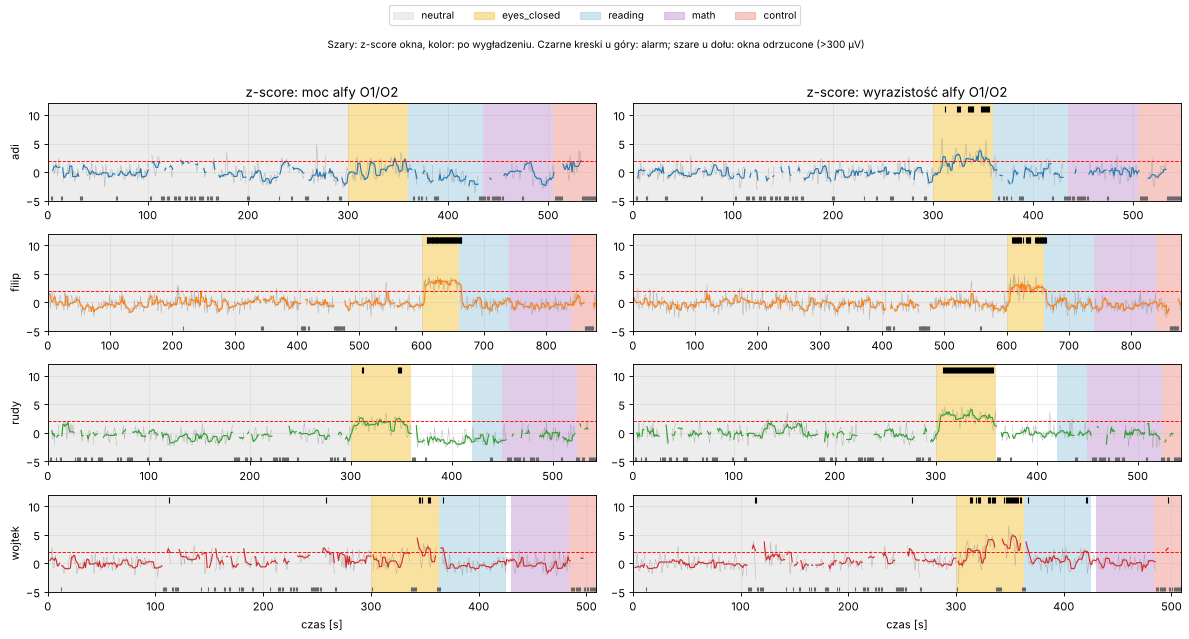

In [9]:
def shade_blocks(ax, L, alpha=0.5):
    for _, a in L.iterrows():
        ax.axvspan(a.onset, a.onset + a.duration, color=BLOCK_COLORS[a.description], alpha=alpha, lw=0)


fig, axes = plt.subplots(4, 2, figsize=(15, 8))
for i, n in enumerate(tables):
    for j, col in enumerate(FEATURES):
        ax = axes[i, j]; T = D[col][n]
        shade_blocks(ax, labels[n])
        ax.plot(T.t_end, T.z.clip(-5, 12), lw=0.4, color="gray", alpha=0.6)
        ax.plot(T.t_end, T.zs.clip(-5, 12), lw=1.0, color=PERSON_COLORS[n])
        ax.plot(T.t_end[T.alarm], np.full(T.alarm.sum(), 11), "|", color="k", ms=6)
        ax.plot(T.t_end[T.bad], np.full(T.bad.sum(), -4.5), "|", color="dimgray", ms=4)
        ax.axhline(Z_SLEEPY, color="r", ls="--", lw=0.8)
        ax.set_ylim(-5, 12); ax.set_xlim(0, T.t_end.max())
        if i == 0: ax.set_title(f"z-score: {FEATURES[col]}")
        if j == 0: ax.set_ylabel(n)
axes[-1, 0].set_xlabel("czas [s]"); axes[-1, 1].set_xlabel("czas [s]")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in BLOCK_COLORS.values()]
fig.legend(handles, BLOCK_COLORS.keys(), loc="upper center", ncol=5, fontsize=9)
fig.suptitle("Szary: z-score okna, kolor: po wygładzeniu. Czarne kreski u góry: alarm; szare u dołu: okna odrzucone (>300 µV)",
             y=0.945, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

## 4. Kontrast `reading` i `math` wobec `neutral`

Dla każdej osoby porównujemy czyste okna bloku z czystymi oknami bazy. Miara: *d* Cohena (różnica średnich przez wspólne odchylenie) na wartościach log10. Okna nakładają się w połowie i są ze sobą skorelowane, więc *d* jest opisem wielkości różnicy, a nie testem. Przy 4 osobach liczymy tylko, u ilu osób kierunek jest ten sam.

Bazy:

- **`neutral` (cały)**: to rozmowa i ruch, więc baza jest głośna: jest w niej EMG mowy i ruch głowy (patrz tabela EMG niżej).
- **`neutral` spokojny**: okna `neutral`, w których zarówno EMG 60–95 Hz, jak i ruch z akcelerometru są poniżej mediany tej osoby w `neutral`. To przybliża fragmenty bez mówienia i ruchu. Uzasadnienie: mowa i ruch podnoszą właśnie te dwie miary. Wada: wybór okien według sygnału może przesunąć też inne pasma, więc to tylko test odporności wniosku.
- **`math` kontra `reading`**: oba bloki to siedzenie z otwartymi oczami bez rozmowy, więc to najczystsze porównanie, jakie mamy.

`engagement` i `fatigue` to ta sama wielkość odwrócona (log10 jednej = minus log10 drugiej), więc ich *d* różnią się tylko znakiem. Pokazujemy obie, bo pipeline używa (theta+alfa)/beta jako znacznika zmęczenia.

In [10]:
CONTRAST_FEATS = {"theta_front": "theta czołowa F3/F4", "alpha_par": "alfa ciemieniowa P3/P4",
                  "alpha_occ": "alfa potyliczna O1/O2", "engagement": "beta/(alfa+theta)",
                  "fatigue": "(theta+alfa)/beta", "emg": "EMG 60–95 Hz"}


def cohen_d(a, b):
    a, b = np.asarray(a), np.asarray(b)
    s = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / s


def baseline(T, kind):
    c = T[~T.bad]
    if kind == "neutral":
        return c[c.block == "neutral"]
    if kind == "neutral spokojny":
        nb = c[c.block == "neutral"]
        return nb[(nb.emg < nb.emg.median()) & (nb.jerk < nb.jerk.median())]
    return c[c.block == kind]


comparisons = [("reading", "neutral"), ("math", "neutral"), ("reading", "neutral spokojny"),
               ("math", "neutral spokojny"), ("math", "reading")]
rows = []
for n, T in tables.items():
    c = T[~T.bad]
    for task, base in comparisons:
        a, b = c[c.block == task], baseline(T, base)
        for f, name in CONTRAST_FEATS.items():
            rows.append(dict(osoba=n, porownanie=f"{task} − {base}", cecha=name, d=cohen_d(a[f], b[f]),
                             n_a=len(a), n_b=len(b)))
C = pd.DataFrame(rows)
order = list(CONTRAST_FEATS.values())
dtab = C.pivot_table(index=["porownanie", "cecha"], columns="osoba", values="d")
dtab = dtab.reindex(pd.MultiIndex.from_product([[f"{a} − {b}" for a, b in comparisons], order]))
dtab["ten sam znak"] = dtab[list(tables)].apply(
    lambda r: f"{max((r > 0).sum(), (r < 0).sum())}/4 ({'+' if (r > 0).sum() >= (r < 0).sum() else '−'})", axis=1)
dtab["średnie d"] = dtab[list(tables)].mean(1)
display(dtab.round(2))
C.groupby(["porownanie", "osoba"])[["n_a", "n_b"]].first().unstack("osoba")

osoba                                               adi  filip  rudy  wojtek  \
reading − neutral          theta czołowa F3/F4    -0.43  -0.51 -0.78   -1.13   
                           alfa ciemieniowa P3/P4 -0.72  -0.66 -0.89   -0.63   
                           alfa potyliczna O1/O2  -0.78  -0.17 -0.79   -0.59   
                           beta/(alfa+theta)      -0.06   0.04  0.74    0.91   
                           (theta+alfa)/beta       0.06  -0.04 -0.74   -0.91   
                           EMG 60–95 Hz           -0.44  -0.75 -0.59   -0.58   
math − neutral             theta czołowa F3/F4     0.05  -0.60  0.13   -0.23   
                           alfa ciemieniowa P3/P4 -0.03  -0.04 -0.08   -0.53   
                           alfa potyliczna O1/O2  -0.37  -0.46  0.14   -0.41   
                           beta/(alfa+theta)      -1.95   0.19  0.39    0.19   
                           (theta+alfa)/beta       1.95  -0.19 -0.39   -0.19   
                           EMG 60–95 Hz           -2.93  -0.44  1.80   -0.12   
reading − neutral spokojny theta czołowa F3/F4     0.19   0.09 -0.37   -0.60   
                           alfa ciemieniowa P3/P4 -0.47  -0.70 -0.78   -0.04   
                           alfa potyliczna O1/O2  -0.42   0.05 -0.66   -0.29   
                           beta/(alfa+theta)      -0.20   0.23  0.57    0.75   
                           (theta+alfa)/beta       0.20  -0.23 -0.57   -0.75   
                           EMG 60–95 Hz            0.34   0.06  0.61    0.88   
math − neutral spokojny    theta czołowa F3/F4     0.86  -0.01  0.50    0.49   
                           alfa ciemieniowa P3/P4  0.41  -0.13  0.03    0.04   
                           alfa potyliczna O1/O2   0.08  -0.25  0.29   -0.08   
                           beta/(alfa+theta)      -2.37   0.38  0.24   -0.12   
                           (theta+alfa)/beta       2.37  -0.38 -0.24    0.12   
                           EMG 60–95 Hz           -2.60   0.40  4.02    2.51   
math − reading             theta czołowa F3/F4     0.53  -0.11  1.10    1.00   
                           alfa ciemieniowa P3/P4  0.77   0.64  0.75    0.08   
                           alfa potyliczna O1/O2   0.42  -0.33  0.88    0.17   
                           beta/(alfa+theta)      -1.73   0.17 -0.36   -0.70   
                           (theta+alfa)/beta       1.73  -0.17  0.36    0.70   
                           EMG 60–95 Hz           -1.98   0.30  3.50    0.88   

osoba                                             ten sam znak  średnie d  
reading − neutral          theta czołowa F3/F4         4/4 (−)      -0.71  
                           alfa ciemieniowa P3/P4      4/4 (−)      -0.72  
                           alfa potyliczna O1/O2       4/4 (−)      -0.58  
                           beta/(alfa+theta)           3/4 (+)       0.41  
                           (theta+alfa)/beta           3/4 (−)      -0.41  
                           EMG 60–95 Hz                4/4 (−)      -0.59  
math − neutral             theta czołowa F3/F4         2/4 (+)      -0.16  
                           alfa ciemieniowa P3/P4      4/4 (−)      -0.17  
                           alfa potyliczna O1/O2       3/4 (−)      -0.28  
                           beta/(alfa+theta)           3/4 (+)      -0.30  
                           (theta+alfa)/beta           3/4 (−)       0.30  
                           EMG 60–95 Hz                3/4 (−)      -0.42  
reading − neutral spokojny theta czołowa F3/F4         2/4 (+)      -0.17  
                           alfa ciemieniowa P3/P4      4/4 (−)      -0.50  
                           alfa potyliczna O1/O2       3/4 (−)      -0.33  
                           beta/(alfa+theta)           3/4 (+)       0.34  
                           (theta+alfa)/beta           3/4 (−)      -0.34  
                           EMG 60–95 Hz                4/4 (+)       0.47  
math − neutral spokojny    theta czołowa F3/F4         3/4 (+)       0.46  

n_a                    n_b                  
osoba                      adi filip rudy wojtek  adi filip rudy wojtek
porownanie                                                             
math − neutral              52    99   47     53  239   568  225    250
math − neutral spokojny     52    99   47     53   91   161   95     85
math − reading              52    99   47     53   55    79   26     61
reading − neutral           55    79   26     61  239   568  225    250
reading − neutral spokojny  55    79   26     61   91   161   95     85

### Poziom EMG i ruchu w blokach (mediana, względem `neutral` tej osoby)

In [11]:
rows = []
for n, T in tables.items():
    c = T[~T.bad]; nb = c[c.block == "neutral"]
    for b in BLOCKS:
        cb = c[c.block == b]
        rows.append(dict(osoba=n, blok=b, **{"EMG [dB wzgl. neutral]": 10 * (cb.emg.median() - nb.emg.median()),
                                            "ruch [x neutral]": cb.jerk.median() / nb.jerk.median()}))
E = pd.DataFrame(rows)
E.pivot(index="osoba", columns="blok").reindex(columns=BLOCKS, level=1).round(1)

EMG [dB wzgl. neutral]                                   \
blok                  neutral eyes_closed reading math control   
osoba                                                            
adi                       0.0        -0.4     0.4 -9.8    16.5   
filip                     0.0         3.8    -4.0 -3.8    14.1   
rudy                      0.0         0.1    -2.7  6.7    17.3   
wojtek                    0.0         2.7    -2.8  0.0    15.2   

       ruch [x neutral]                                   
blok            neutral eyes_closed reading math control  
osoba                                                     
adi                 1.0         0.4     0.7  0.5     0.4  
filip               1.0         0.7     0.7  0.6     1.6  
rudy                1.0         0.6     0.8  1.3     0.8  
wojtek              1.0         1.4     0.3  1.0     0.6

### Wykres efektów

Każdy punkt to jedna osoba. Linia pionowa w zerze: brak różnicy.

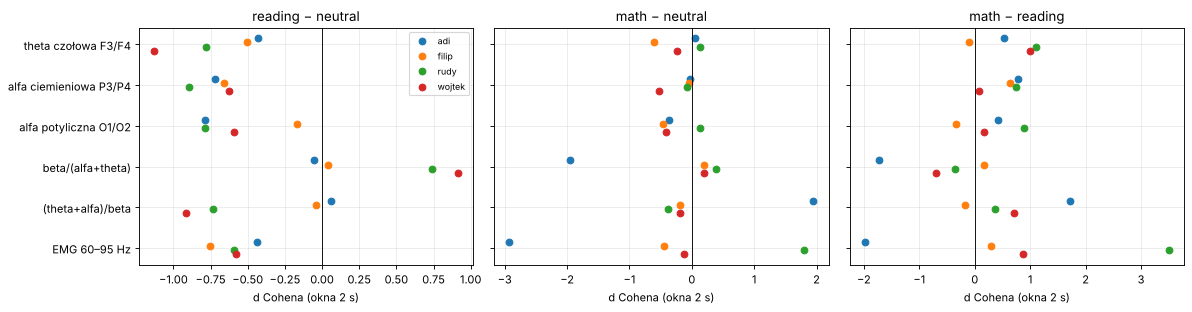

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
offs = {"adi": -0.15, "filip": -0.05, "rudy": 0.05, "wojtek": 0.15}
for ax, comp in zip(axes, ["reading − neutral", "math − neutral", "math − reading"]):
    sub = C[C.porownanie == comp]
    for k, name in enumerate(order):
        for n in tables:
            v = sub[(sub.cecha == name) & (sub.osoba == n)].d.iloc[0]
            ax.plot(v, k + offs[n], "o", color=PERSON_COLORS[n], label=n if k == 0 else None)
    ax.axvline(0, color="k", lw=0.8); ax.set_title(comp); ax.set_xlabel("d Cohena (okna 2 s)")
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
axes[0].invert_yaxis(); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Czy (theta+alfa)/beta mierzy mózg, czy mięśnie?

Beta (13–30 Hz) na elektrodach suchych łatwo łapie napięcie mięśni. Sprawdzamy dwie rzeczy: korelację log (theta+alfa)/beta z mocą EMG 60–95 Hz w czystych oknach każdej osoby (spoza `eyes_closed`) oraz to, czy *d* znacznika zmęczenia w kontrastach idzie w parze z *d* EMG.

In [13]:
rows = []
for n, T in tables.items():
    c = T[~T.bad & T.block.isin(["neutral", "reading", "math", "control"])]
    rows.append(dict(osoba=n, **{"r((θ+α)/β, EMG)": np.corrcoef(c.fatigue, c.emg)[0, 1],
                                 "r(theta czołowa, EMG)": np.corrcoef(c.theta_front, c.emg)[0, 1],
                                 "r(alfa O1/O2, EMG)": np.corrcoef(c.alpha_occ, c.emg)[0, 1]}))
display(pd.DataFrame(rows).set_index("osoba").round(2))
pv = C.pivot_table(index=["porownanie", "osoba"], columns="cecha", values="d")
print(f"korelacja d((θ+α)/β) z d(EMG) po 20 parach osoba×porównanie: "
      f"r = {np.corrcoef(pv['(theta+alfa)/beta'], pv['EMG 60–95 Hz'])[0, 1]:.2f}")

,"r((θ+α)/β, EMG)","r(theta czołowa, EMG)","r(alfa O1/O2, EMG)"
osoba,,,
adi,-0.51,0.41,0.47
filip,-0.55,0.50,0.23
rudy,-0.01,0.40,0.26
wojtek,-0.07,0.33,0.27


korelacja d((θ+α)/β) z d(EMG) po 20 parach osoba×porównanie: r = -0.51


### Stara reguła „przeciążony” w bloku `math`

Notebook 02 i poprzednia wersja tego notebooka sprawdzały regułę: theta czołowa z > 2 i alfa ciemieniowa z < −1 (po kalibracji 60 okien i medianie z 5). Teraz mamy blok liczenia, więc patrzymy, jak często reguła zapala się w `math` i poza nim. To tylko obserwacja: tej reguły nie używamy w produkcie.

In [14]:
rows = []
for n, T in tables.items():
    ok = ~T.bad; base = T[ok].iloc[:CAL_WINDOWS]
    z = {f: ((T[f] - base[f].mean()) / base[f].std()).where(ok).rolling(SMOOTH, min_periods=1).median()
         for f in ["theta_front", "alpha_par"]}
    over = (z["theta_front"] > 2) & (z["alpha_par"] < -1) & ok
    rows.append({"osoba": n, **{b: 100 * over[ok & (T.block == b)].mean() for b in BLOCKS}})
pd.DataFrame(rows).set_index("osoba").round(1).rename(columns=lambda b: f"{b} [% okien]")

,neutral [% okien],eyes_closed [% okien],reading [% okien],math [% okien],control [% okien]
osoba,,,,,
adi,0.0,0.0,0.0,0.0,0.0
filip,0.0,0.0,0.0,0.0,0.0
rudy,0.0,0.0,0.0,0.0,0.0
wojtek,0.0,0.0,0.0,0.0,0.0


## 5. Blok `control`: mrugnięcia, zaciskanie szczęki, ruch głowy

Blok nie ma znaczników wewnątrz, więc **nie przypisujemy zdarzeń do konkretnych sekund**. Pokazujemy przebieg w czasie od 20 s przed `math` do końca nagrania i porównujemy blok jako całość z `neutral`. Czego się spodziewamy:

- zamykanie oczu: alfa na O1/O2 i ruchy gałek ocznych; referencja jest na Fp1 (czoło), więc mrugnięcia mogą wchodzić do **wszystkich** kanałów przez referencję, nie tylko do F3/F4,
- zaciskanie szczęki: wybuch EMG 60–95 Hz bez dużego ruchu akcelerometru,
- kręcenie głową: duży ruch akcelerometru, wolne fale i duża amplituda.

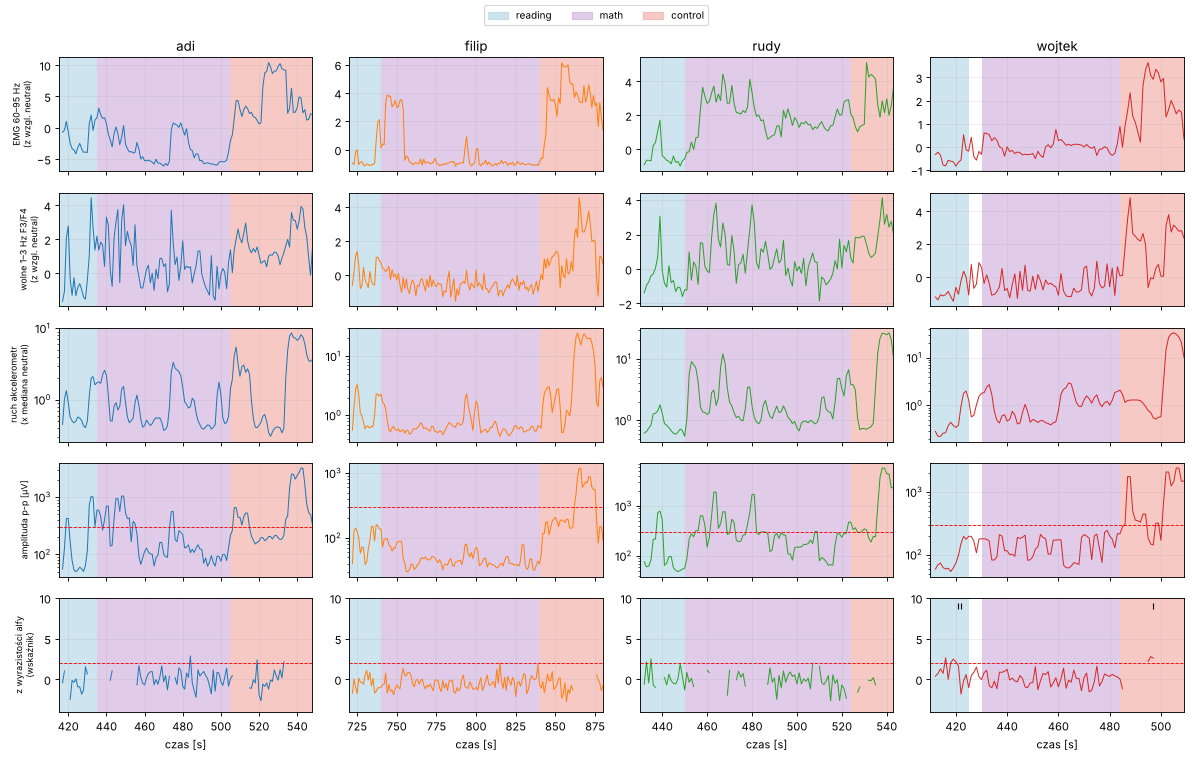

In [15]:
def robust_z(x, ref):
    return (x - ref.median()) / ((ref - ref.median()).abs().median() * 1.4826)


fig, axes = plt.subplots(5, 4, figsize=(15, 9.5), sharex="col")
for j, n in enumerate(tables):
    T = D["prom_occ"][n]; L = labels[n]
    t0 = L[L.description == "math"].onset.iloc[0] - 20
    nb = T[(T.block == "neutral") & ~T.bad]
    rows = [("EMG 60–95 Hz\n(z wzgl. neutral)", robust_z(T.emg, nb.emg)),
            ("wolne 1–3 Hz F3/F4\n(z wzgl. neutral)", robust_z(T.lf_front, nb.lf_front)),
            ("ruch akcelerometr\n(x mediana neutral)", T.jerk / nb.jerk.median()),
            ("amplituda p-p [µV]", T.ptp),
            ("z wyrazistości alfy\n(wskaźnik)", T.z)]
    for i, (name, y) in enumerate(rows):
        ax = axes[i, j]; m = T.t >= t0
        shade_blocks(ax, L[L.onset + L.duration > t0])
        ax.plot(T.t_end[m], y[m], lw=0.9, color=PERSON_COLORS[n])
        if i == 2: ax.set_yscale("log")
        if i == 3: ax.axhline(REJECT_UV, color="r", ls="--", lw=0.8); ax.set_yscale("log")
        if i == 4:
            ax.axhline(Z_SLEEPY, color="r", ls="--", lw=0.8)
            ax.plot(T.t_end[m & T.alarm], np.full((m & T.alarm).sum(), 9), "|", color="k")
            ax.set_ylim(-4, 10)
        if j == 0: ax.set_ylabel(name, fontsize=8)
        ax.set_xlim(t0, T.t_end.max())
    axes[0, j].set_title(n)
    axes[-1, j].set_xlabel("czas [s]")
handles = [plt.Rectangle((0, 0), 1, 1, color=BLOCK_COLORS[b], alpha=0.5) for b in ["reading", "math", "control"]]
fig.legend(handles, ["reading", "math", "control"], loc="upper center", ncol=3, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

### Surowy sygnał w bloku `control`

F3, F4 (kolor) i O1, O2 (czarne) po filtrze 1–40 Hz. Skala wspólna, żeby było widać, które zjawiska są na wszystkich kanałach naraz.

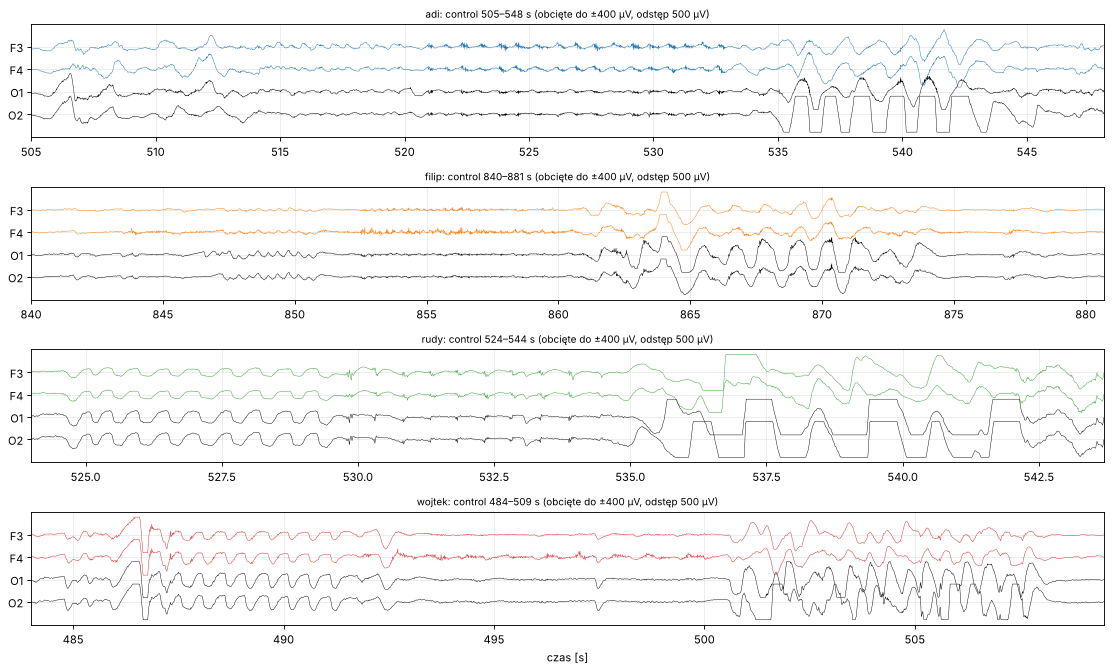

In [16]:
fig, axes = plt.subplots(4, 1, figsize=(14, 8.5))
for ax, n in zip(axes, raws):
    L = labels[n]; c = L[L.description == "control"].iloc[0]
    r = raws[n].copy().pick(["F3", "F4", "O1", "O2"]).filter(1, 40, verbose=False).crop(c.onset, raws[n].times[-1])
    x = r.get_data() * 1e6; t = r.times + c.onset
    for k, ch in enumerate(r.ch_names):
        ax.plot(t[::3], np.clip(x[k, ::3], -400, 400) - k * 500, lw=0.4, color=PERSON_COLORS[n] if k < 2 else "k")
    ax.set_yticks([-k * 500 for k in range(4)]); ax.set_yticklabels(r.ch_names)
    ax.set_title(f"{n}: control {c.onset:.0f}–{c.onset + c.duration:.0f} s (obcięte do ±400 µV, odstęp 500 µV)", fontsize=9)
    ax.set_xlim(c.onset, t[-1])
axes[-1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()

### `control` jako całość: porównanie z `neutral`

In [17]:
rows = []
for n in tables:
    T = D["prom_occ"][n]; Ta = D["alpha_occ"][n]
    nb = T[(T.block == "neutral") & ~T.bad]
    for b in ["neutral", "control"]:
        allb = T[T.block == b]; cb = allb[~allb.bad]
        hi_emg = robust_z(allb.emg, nb.emg) > 3
        hi_mov = allb.jerk > 3 * nb.jerk.median()
        rows.append({"osoba": n, "blok": b, "okna": len(allb), "czyste okna": len(cb),
                     "odrzucone [%]": 100 * allb.bad.mean(),
                     "EMG z>3 [% okien]": 100 * hi_emg.mean(),
                     "EMG z>3: odrzucone [%]": 100 * allb.bad[hi_emg].mean() if hi_emg.any() else np.nan,
                     "ruch >3x [% okien]": 100 * hi_mov.mean(),
                     "ruch >3x: odrzucone [%]": 100 * allb.bad[hi_mov].mean() if hi_mov.any() else np.nan,
                     "wolne F3/F4 [dB wzgl. neutral]": 10 * (allb.lf_front.median() - nb.lf_front.median()),
                     "wolne O1/O2 [dB wzgl. neutral]": 10 * (allb.lf_occ.median() - nb.lf_occ.median()),
                     "flagi 'senny', wyrazistość [% czystych]": 100 * T.flag[cb.index].mean() if len(cb) else np.nan,
                     "flagi 'senny', moc alfy [% czystych]": 100 * Ta.flag[cb.index].mean() if len(cb) else np.nan,
                     "alarmy (wyrazistość)": int(T.alarm_on[allb.index].sum()),
                     "alarmy (moc alfy)": int(Ta.alarm_on[allb.index].sum())})
pd.DataFrame(rows).set_index(["osoba", "blok"]).round(1).T

osoba                                       adi           filip          \
blok                                    neutral control neutral control   
okna                                      299.0    42.0   599.0    39.0   
czyste okna                               239.0    19.0   568.0    25.0   
odrzucone [%]                              20.1    54.8     5.2    35.9   
EMG z>3 [% okien]                          12.4    52.4     7.0    79.5   
EMG z>3: odrzucone [%]                     51.4    45.5    19.0    41.9   
ruch >3x [% okien]                          7.7    42.9    12.0    48.7   
ruch >3x: odrzucone [%]                    69.6   100.0    26.4    73.7   
wolne F3/F4 [dB wzgl. neutral]              1.9     8.4     0.4     7.3   
wolne O1/O2 [dB wzgl. neutral]              1.4     8.0     0.4    11.5   
flagi 'senny', wyrazistość [% czystych]     0.0     0.0     0.0     0.0   
flagi 'senny', moc alfy [% czystych]        0.4     5.3     0.0     0.0   
alarmy (wyrazistość)                        0.0     0.0     0.0     0.0   
alarmy (moc alfy)                           0.0     0.0     0.0     0.0   

osoba                                      rudy          wojtek          
blok                                    neutral control neutral control  
okna                                      299.0    18.0   299.0    24.0  
czyste okna                               225.0     6.0   250.0     4.0  
odrzucone [%]                              24.7    66.7    16.4    83.3  
EMG z>3 [% okien]                           0.0    33.3     0.0    20.8  
EMG z>3: odrzucone [%]                      NaN    33.3     NaN    60.0  
ruch >3x [% okien]                         14.7    55.6     4.0    37.5  
ruch >3x: odrzucone [%]                    45.5    90.0    66.7   100.0  
wolne F3/F4 [dB wzgl. neutral]              1.9    13.9     1.9    12.2  
wolne O1/O2 [dB wzgl. neutral]              2.1    14.4     1.7    14.0  
flagi 'senny', wyrazistość [% czystych]     0.0     0.0     3.2   100.0  
flagi 'senny', moc alfy [% czystych]        0.0     0.0     3.6     0.0  
alarmy (wyrazistość)                        0.0     0.0     2.0     1.0  
alarmy (moc alfy)                           0.0     0.0     2.0     0.0

### Na których kanałach widać `control`

Mediana mocy w całym bloku `control` (także okna odrzucone) względem mediany czystych okien `neutral`, w dB, osobno dla każdego kanału. Średnia z 4 osób.

In [18]:
rows = []
for n, r in raws.items():
    L = labels[n]; T = tables[n]
    eh = clean_windows(r.copy().pick(OUR_CH).filter(1, None, verbose=False))
    fh, ph = welch(eh.get_data(), FS, nperseg=int(WIN_S * FS), axis=-1)
    emg_ch = np.log10(ph[:, :, (fh >= 60) & (fh <= 95)].mean(-1))
    lf_ch = np.log10(band_power(fh, ph, 1, 3))
    ctrl, neu = (T.block == "control").values, ((T.block == "neutral") & ~T.bad).values
    for name, v in [("EMG 60–95 Hz", emg_ch), ("wolne 1–3 Hz", lf_ch)]:
        rows.append(dict(osoba=n, miara=name, **dict(zip(OUR_CH, 10 * (np.median(v[ctrl], 0) - np.median(v[neu], 0))))))
CH = pd.DataFrame(rows)
display(CH.groupby("miara")[OUR_CH].mean().round(1))
CH.set_index(["miara", "osoba"]).sort_index().round(1)

,F3,F4,C3,C4,P3,P4,O1,O2
miara,,,,,,,,
EMG 60–95 Hz,9.2,9.6,8.3,9.0,9.6,9.0,9.8,9.5
wolne 1–3 Hz,10.5,10.0,11.4,11.4,10.6,11.7,11.5,12.4


F3    F4    C3    C4    P3    P4    O1    O2
miara        osoba                                                 
EMG 60–95 Hz adi      6.8   5.1   8.7   6.0   6.6   7.2   5.3   6.8
             filip   11.9  15.8  13.3  15.1  14.7  10.6  13.5  12.3
             rudy     8.7   9.2   5.6   6.5   9.6   9.2  11.7  11.0
             wojtek   9.2   8.3   5.6   8.5   7.5   8.9   8.6   8.0
wolne 1–3 Hz adi      7.7   7.3   6.7   7.1   5.6   6.2   6.5   9.3
             filip    7.0   8.6   9.5  11.1  10.7  10.8  11.7  11.2
             rudy    14.3  13.1  15.2  13.9  13.1  15.2  14.1  14.5
             wojtek  13.0  10.7  14.2  13.7  12.9  14.8  13.8  14.4

## 6. Epizody alfy z notebooka 01 a prawdziwe `eyes_closed`

Notebook 01 wykrył epizody z samej wyrazistości alfy (z-score względem mediany całego nagrania, próg 2, minimum 8 s), bez wiedzy o protokole.

In [19]:
rows = []
for n, L in labels.items():
    e0, e1 = ec_window(L)
    eps = episodes[episodes.osoba == n]
    for _, e in eps.iterrows():
        a, b = e["start [s]"], e["koniec [s]"]
        ov = max(0, min(b, e1) - max(a, e0))
        rows.append(dict(osoba=n, epizod=f"{a}–{b} s", eyes_closed=f"{e0:.0f}–{e1:.0f} s",
                         wspolne_s=ov, **{"pokrycie bloku [%]": 100 * ov / (e1 - e0),
                                         "epizodu w bloku [%]": 100 * ov / (b - a),
                                         "start epizodu po starcie bloku [s]": a - e0}))
    if not len(eps):
        rows.append(dict(osoba=n, epizod="brak", eyes_closed=f"{e0:.0f}–{e1:.0f} s", wspolne_s=0))
OV = pd.DataFrame(rows).set_index("osoba")
display(OV.round(0))
total_ec = sum(ec_window(L)[1] - ec_window(L)[0] for L in labels.values())
print(f"epizodów: {len(episodes)}, wszystkie w eyes_closed: {bool((OV['epizodu w bloku [%]'] > 90).all())}; "
      f"łączne pokrycie bloków eyes_closed: {100 * OV.wspolne_s.sum() / total_ec:.0f}%")

,epizod,eyes_closed,wspolne_s,pokrycie bloku [%],epizodu w bloku [%],start epizodu po starcie bloku [s]
osoba,,,,,,
adi,340–351 s,300–360 s,11.0,18.0,100.0,40.0
filip,603–661 s,600–660 s,57.0,95.0,98.0,3.0
rudy,301–354 s,300–360 s,53.0,88.0,100.0,1.0
wojtek,324–364 s,300–363 s,39.0,62.0,98.0,24.0


epizodów: 4, wszystkie w eyes_closed: True; łączne pokrycie bloków eyes_closed: 66%


## 7. Wybór kalibracji i odrzucanie artefaktów

Warianty kalibracji (dla obu cech):

- **`cal60`**: pierwsze 60 czystych okien nagrania, czyli początek rozmowy (wariant demo),
- **`cal60_late`**: ostatnie 60 czystych okien `neutral` tuż przed `eyes_closed` (kalibracja „na świeżo”),
- **`full`**: mediana i MAD z całej sesji; ta baza widzi też `eyes_closed`, więc jest optymistyczna.

AUC na surowym z-score nie zależy od kalibracji (przesunięcie i skalowanie nie zmieniają kolejności okien), więc porównujemy miary zależne od progu. Wariant **bez odrzucania** liczy z-score na wszystkich oknach, także tych powyżej 300 µV, i kalibruje na pierwszych 60 oknach bez względu na jakość.

In [20]:
rows = []
for col in FEATURES:
    for n, T in tables.items():
        for method, reject in [("cal60", True), ("cal60_late", True), ("full", True), ("cal60", False)]:
            s = scores(detect(T, col, method, reject), labels[n])
            rows.append(dict(cecha=FEATURES[col], wariant=method + ("" if reject else " bez odrzucania"), osoba=n,
                             **{k: s[k] for k in ["czułość [%]", "fałszywe flagi [% czystego czasu]", "fałszywe alarmy [/min]",
                                                   "alarm w bloku", "opóźnienie [s]", "AUC wygładzone", "control: flagi [%]"]}))
K = pd.DataFrame(rows)
display(K.pivot_table(index=["cecha", "wariant"], columns="osoba",
                      values=["czułość [%]", "fałszywe flagi [% czystego czasu]"]).round(1))
KA = K.drop(columns=["osoba", "alarm w bloku", "opóźnienie [s]"]).groupby(["cecha", "wariant"]).mean().round(2)
KA.insert(0, "alarm w bloku [osoby]", K.groupby(["cecha", "wariant"])["alarm w bloku"].sum().astype(int).astype(str) + "/4")
KA.insert(1, "opóźnienie, mediana [s]", K.groupby(["cecha", "wariant"])["opóźnienie [s]"].median())
KA

czułość [%]                     \
osoba                                               adi filip  rudy wojtek   
cecha                  wariant                                               
moc alfy O1/O2         cal60                        3.4  93.2  20.3   18.9   
                       cal60 bez odrzucania         0.0  93.2  15.3   22.6   
                       cal60_late                   0.0  93.2  62.7    3.8   
                       full                         0.0  93.2  18.6    5.7   
wyrazistość alfy O1/O2 cal60                       49.2  81.4  89.8   71.7   
                       cal60 bez odrzucania        49.2  81.4  89.8   66.1   
                       cal60_late                  45.8  91.5  91.5   47.2   
                       full                        25.4  91.5  79.7   41.5   

                                            fałszywe flagi [% czystego czasu]  \
osoba                                                                     adi   
cecha                  wariant                                                  
moc alfy O1/O2         cal60                                              0.3   
                       cal60 bez odrzucania                               1.1   
                       cal60_late                                         0.0   
                       full                                               0.0   
wyrazistość alfy O1/O2 cal60                                              0.0   
                       cal60 bez odrzucania                               0.0   
                       cal60_late                                         0.0   
                       full                                               0.0   

                                                               
osoba                                       filip rudy wojtek  
cecha                  wariant                                 
moc alfy O1/O2         cal60                  0.0  0.0    2.5  
                       cal60 bez odrzucania   1.2  1.0    1.7  
                       cal60_late             0.5  1.7    0.0  
                       full                   0.5  0.0    0.0  
wyrazistość alfy O1/O2 cal60                  0.0  0.0    3.3  
                       cal60 bez odrzucania   0.0  0.0    2.2  
                       cal60_late             0.0  1.0    0.8  
                       full                   0.0  0.0    0.6

alarm w bloku [osoby]  \
cecha                  wariant                                      
moc alfy O1/O2         cal60                                  3/4   
                       cal60 bez odrzucania                   3/4   
                       cal60_late                             2/4   
                       full                                   2/4   
wyrazistość alfy O1/O2 cal60                                  4/4   
                       cal60 bez odrzucania                   4/4   
                       cal60_late                             4/4   
                       full                                   4/4   

                                             opóźnienie, mediana [s]  \
cecha                  wariant                                         
moc alfy O1/O2         cal60                                    11.0   
                       cal60 bez odrzucania                     11.0   
                       cal60_late                                8.5   
                       full                                      9.5   
wyrazistość alfy O1/O2 cal60                                    10.5   
                       cal60 bez odrzucania                     10.5   
                       cal60_late                               10.5   
                       full                                     10.5   

                                             czułość [%]  \
cecha                  wariant                             
moc alfy O1/O2         cal60                       33.95   
                       cal60 bez odrzucania        32.76   
                       cal60_late                  39.93   
                       full                        29.38   
wyrazistość alfy O1/O2 cal60                       73.01   
                       cal60 bez odrzucania        71.62   
                       cal60_late                  69.00   
                       full                        59.53   

                                             fałszywe flagi [% czystego czasu]  \
cecha                  wariant                                                   
moc alfy O1/O2         cal60                                              0.70   
                       cal60 bez odrzucania                               1.25   
                       cal60_late                                         0.55   
                       full                                               0.13   
wyrazistość alfy O1/O2 cal60                                              0.83   
                       cal60 bez odrzucania                               0.55   
                       cal60_late                                         0.46   
                       full                                               0.14   

                                             fałszywe alarmy [/min]  \
cecha                  wariant                                        
moc alfy O1/O2         cal60                                   0.08   
                       cal60 bez odrzucania                    0.15   
                       cal60_late                              0.07   
                       full                                    0.02   
wyrazistość alfy O1/O2 cal60                                   0.12   
                       cal60 bez odrzucania                    0.07   
                       cal60_late                              0.00   
                       full                                    0.00   

                                             AUC wygładzone  \
cecha                  wariant                                
moc alfy O1/O2         cal60                           0.84   
                       cal60 bez odrzucania            0.80   
                       cal60_late                      0.84   
                       full                            0.84   
wyrazistość alfy O1/O2 cal60                           0.94   
                       cal60 bez odrzucania            0.9

In [21]:
shift = []
for col in FEATURES:
    for n, T in tables.items():
        v = T.loc[~T.bad & (T.block == "neutral"), col]
        mu60, sd60 = calibrate(T, col, "cal60")
        mul, sdl = calibrate(T, col, "cal60_late")
        shift.append(dict(cecha=FEATURES[col], osoba=n,
                          **{"przesunięcie cal60_late wzgl. cal60 [σ cal60]": (mul - mu60) / sd60,
                             "σ cal60 / σ całego neutral": sd60 / v.std()}))
pd.DataFrame(shift).round(2).set_index(["cecha", "osoba"])

przesunięcie cal60_late wzgl. cal60 [σ cal60]  \
cecha                  osoba                                                   
moc alfy O1/O2         adi                                             -0.04   
                       filip                                           -0.11   
                       rudy                                            -0.30   
                       wojtek                                           0.94   
wyrazistość alfy O1/O2 adi                                              0.03   
                       filip                                           -0.45   
                       rudy                                            -0.29   
                       wojtek                                           0.51   

                               σ cal60 / σ całego neutral  
cecha                  osoba                               
moc alfy O1/O2         adi                           0.81  
                       filip                         1.10  
                       rudy                          1.05  
                       wojtek                        0.91  
wyrazistość alfy O1/O2 adi                           0.94  
                       filip                         1.03  
                       rudy                          0.93  
                       wojtek                        0.89

## 8. Wykres na slajd

Jeden wykres: wyrazistość alfy (z-score względem 60 s kalibracji, po wygładzeniu) u czterech osób, z kolorowymi blokami protokołu i alarmami. Zapisujemy do `docs/img/`, jeśli notebook działa w repo.

zapisano ../../docs/img/eyes-closed-detection-labelled-blocks-4-people.png 167 kB


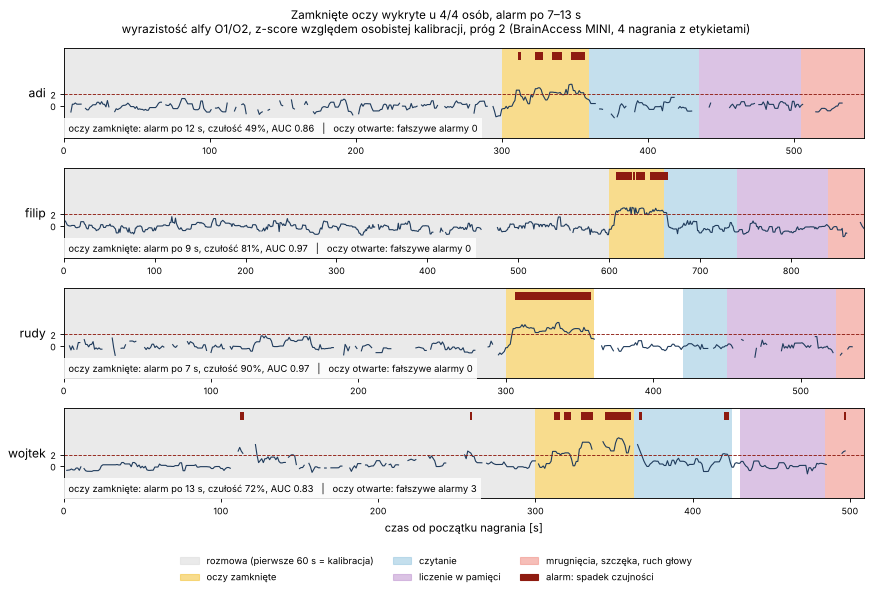

In [22]:
import matplotlib.patches as mpatches

col = "prom_occ"
R = res[res.cecha == FEATURES[col]].set_index("osoba")
fig, axes = plt.subplots(4, 1, figsize=(11, 7.4), sharex=False)
for ax, n in zip(axes, tables):
    T = D[col][n]; L = labels[n]; s = R.loc[n]
    shade_blocks(ax, L, alpha=0.6)
    ax.plot(T.t_end, T.zs.clip(-5.5, 10), lw=1.0, color="#1f3b5c")
    ta = T.t_end[T.alarm]
    ax.bar(ta, 1.4, bottom=7.9, width=max(1.0, T.t_end.max() / 300), color="#8e1b10", lw=0)
    ax.axhline(Z_SLEEPY, color="#8e1b10", ls="--", lw=0.8)
    ax.set_ylim(-5.5, 10); ax.set_xlim(0, T.t_end.max()); ax.grid(False)
    ax.set_ylabel(n, rotation=0, ha="right", va="center", fontsize=11)
    ax.set_yticks([0, 2]); ax.tick_params(labelsize=8)
    lat = f"alarm po {s['opóźnienie [s]']:.0f} s" if s["alarm w bloku"] else "brak alarmu"
    ax.text(0.006, 0.04, f"oczy zamknięte: {lat}, czułość {s['czułość [%]']:.0f}%, AUC {s['AUC okno']:.2f}   |   "
            f"oczy otwarte: fałszywe alarmy {s['fałszywe alarmy [liczba]']}",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5, bbox=dict(facecolor="white", alpha=0.85, lw=0))
axes[-1].set_xlabel("czas od początku nagrania [s]")
legend = [mpatches.Patch(color=BLOCK_COLORS[b], alpha=0.6, label=lab) for b, lab in
          [("neutral", "rozmowa (pierwsze 60 s = kalibracja)"), ("eyes_closed", "oczy zamknięte"),
           ("reading", "czytanie"), ("math", "liczenie w pamięci"), ("control", "mrugnięcia, szczęka, ruch głowy")]]
legend.append(mpatches.Patch(color="#8e1b10", label="alarm: spadek czujności"))
fig.legend(handles=legend, loc="lower center", ncol=3, fontsize=8.5, frameon=False)
n_ok = int(R["alarm w bloku"].sum())
fig.suptitle(f"Zamknięte oczy wykryte u {n_ok}/4 osób, alarm po {R['opóźnienie [s]'].min():.0f}–{R['opóźnienie [s]'].max():.0f} s\n"
             "wyrazistość alfy O1/O2, z-score względem osobistej kalibracji, próg 2 (BrainAccess MINI, 4 nagrania z etykietami)",
             fontsize=10.5)
plt.tight_layout(rect=(0, 0.07, 1, 1))
img_dir = Path("../../docs/img")
if img_dir.exists():
    out = img_dir / "eyes-closed-detection-labelled-blocks-4-people.png"
    fig.savefig(out, dpi=100)
    print("zapisano", out, f"{out.stat().st_size / 1024:.0f} kB")
plt.show()

## Wnioski

Wszystkie liczby poniżej pochodzą z komórek powyżej. Próba to 4 osoby i po jednym bloku `eyes_closed` na osobę, więc to wynik pilotażowy, a nie walidacja.

**1. Zamknięte oczy: wskaźnik działa u 4/4 osób, ale tylko na wyrazistości alfy.**

- Z **wyrazistością alfy** O1/O2 (kalibracja: pierwsze 60 czystych okien rozmowy, próg z = 2, mediana z 5 okien, alarm po 3 s) alarm włącza się w `eyes_closed` u wszystkich czterech osób, **7–13 s** po zamknięciu oczu (mediana 10,5 s; adi 12, filip 9, rudy 7, wojtek 13 s).
- Czułość na poziomie okien: adi 49%, filip 81%, rudy 90%, wojtek 72% (średnio 73%). U adi i wojtka alarm w bloku jest przerywany.
- AUC `eyes_closed` kontra reszta oznaczonych okien: 0,86 / 0,97 / 0,97 / 0,83 dla pojedynczego okna 2 s i 0,93 / 0,97 / 0,99 / 0,87 po wygładzeniu (adi / filip / rudy / wojtek). Dla wszystkich osób razem, ze wspólnym progiem po kalibracji osobistej: 0,92 i 0,95.
- Fałszywe alarmy przy otwartych oczach (`neutral`, `reading`, `math`): **0 u adi, filipa i rudego, 3 u wojtka**. Dwa z nich (113 s i 259 s, rozmowa) przychodzą zaraz po serii odrzuconych okien (3–4 z 8 poprzednich), trzeci (421 s, czytanie) bez widocznego artefaktu. Średnio 0,12 alarmu na minutę (wojtek 0,5/min), fałszywe flagi to 0,83% czystego czasu (wojtek 3,3%). W `math` nie ma ani jednej flagi.
- **Moc alfy** (pierwotna cecha wskaźnika v0) jest wyraźnie gorsza: AUC 0,64 / 0,98 / 0,91 / 0,65 (łącznie 0,80), czułość średnio 34%, u adi brak alarmu, u wojtka alarm dopiero po 45 s. Dobrze działa tylko u filipa i rudego. Wyrazistość dzieli moc alfy przez sąsiednie pasma, więc nie rośnie razem z szerokopasmowym szumem i zmianą ogólnego poziomu sygnału. **Wniosek dla pipeline'u: szybki wskaźnik liczymy z wyrazistości alfy, nie z mocy alfy.**

**2. Epizody z notebooka 01 trafiły w prawdziwe bloki, ale są za krótkie.** Każdy z 4 epizodów wykrytych z samego sygnału leży w bloku `eyes_closed` (98–100% długości epizodu w bloku), nie ma ani jednego epizodu poza blokiem. Epizody pokrywają jednak tylko 18% bloku u adi, 95% u filipa, 88% u rudego i 62% u wojtka (łącznie 66%), a u adi i wojtka zaczynają się 40 s i 24 s po zamknięciu oczu. Hipoteza z notebooka 01 jest więc potwierdzona co do miejsca, a słabsza alfa u adi i wojtka to cecha tych nagrań, nie błąd etykiet.

**3. Czytanie i liczenie wobec rozmowy (obserwacja, n = 4).**

- `reading` − `neutral`: niższa theta czołowa (4/4, *d* od −0,43 do −1,13), niższa alfa ciemieniowa (4/4, od −0,63 do −0,89), niższa alfa potyliczna (4/4, od −0,17 do −0,79) i niższe EMG (4/4, od −0,44 do −0,75). Po zmianie bazy na spokojne okna rozmowy alfa ciemieniowa nadal jest niższa u 4/4 (średnio *d* = −0,50), ale theta czołowa już nie (2/4). Spadek theta wynikał więc głównie z głośnej bazy.
- `math` − `neutral`: brak spójnego obrazu. Theta czołowa zmienia się w różne strony (2/4), alfa ciemieniowa spada u 4/4, ale minimalnie (*d* od −0,03 do −0,53, średnio −0,17).
- `math` − `reading` (najczystsze porównanie, w obu blokach siedzenie bez rozmowy): wyższa theta czołowa u 3/4 (0,53; 1,10; 1,00; filip −0,11) i wyższa alfa ciemieniowa u 4/4 (0,08–0,77). Przy 4 osobach i jednym bloku na osobę to tylko kierunek do sprawdzenia.
- **Stara reguła „przeciążony” (theta z > 2 i alfa ciemieniowa z < −1) nie zapaliła się ani razu, także w `math`.** Wcześniej tłumaczyliśmy to brakiem zadania. Teraz zadanie było, a reguła i tak milczy, co potwierdza decyzję, żeby przeciążenia nie obiecywać.
- **(theta+alfa)/beta w dużej mierze śledzi napięcie mięśni.** W oknach adi i filipa jego korelacja z EMG 60–95 Hz wynosi −0,51 i −0,55 (u rudego −0,01, u wojtka −0,07). W kontrastach zmiana tego wskaźnika idzie odwrotnie do zmiany EMG (r = −0,51 po 20 parach osoba×porównanie). Najmocniej u adi: w `math` EMG spada o 9,8 dB wobec rozmowy, a (theta+alfa)/beta rośnie z *d* = 1,95. Wolny wskaźnik zmęczenia z planu trzeba więc liczyć na oknach bez EMG albo z korektą na EMG, inaczej pokaże „zmęczenie”, gdy ktoś przestanie mówić.
- Rozmowa jako baza jest głośna: EMG w `reading` jest niższe niż w `neutral` u 3/4 osób (−2,7 do −4,0 dB). U rudego w `math` EMG jest wyższe o 6,7 dB, a ruch 1,3 razy większy niż w rozmowie (36% okien odrzuconych). Nie wiemy, czy liczył na głos.

**4. Blok `control` (mrugnięcia i zamykanie oczu, szczęka, ruch głowy).**

- Cały blok wobec rozmowy: EMG 60–95 Hz wyżej o 14–17 dB, wolne fale 1–3 Hz wyżej o 7–14 dB na F3/F4 i 8–14 dB na O1/O2. Wzrost jest podobny na wszystkich 8 kanałach (średnio EMG +8,3 do +9,8 dB, wolne fale +10,0 do +12,4 dB na kanał). **Przy referencji Fp1 na czole artefakty oczu i mięśni czoła wchodzą do wszystkich kanałów przez referencję**, więc nie da się ich zlokalizować na F3/F4 i nie widać ich słabiej na O1/O2.
- W przebiegu czasu i w surowym sygnale widać kolejno trzy wzorce: rytmiczne wolne wychylenia na wszystkich kanałach przy małym ruchu akcelerometru (pasuje do mrugania i zamykania oczu), wybuchy aktywności wysokoczęstotliwościowej (pasuje do zaciskania szczęki) i duże wolne wahania ponad ±400 µV razem z silnym ruchem akcelerometru (pasuje do kręcenia głową, a na samym końcu może się nakładać zdejmowanie czapki). Kolejność zgadza się z protokołem, ale to interpretacja, a nie etykiety.
- Próg 300 µV odrzuca 36–83% okien `control` (w rozmowie 5–25%). Łapie ruch głowy (odrzucone 74–100% okien z dużym ruchem), ale **słabo łapie napięcie mięśni**: z okien z wysokim EMG odrzuca tylko 33–60%, bo EMG leży głównie powyżej 40 Hz, a amplitudę liczymy po filtrze 1–40 Hz. Mruganie też częściowo przechodzi.
- Fałszywe flagi „senny” w `control`: wyrazistość alfy u adi, filipa i rudego 0%, moc alfy u adi 5,3% czystych okien, bez alarmu. Jedyny alarm to wojtek, 497 s (4 czyste okna w bloku, wszystkie oflagowane), i nie wiemy, czy to artefakt, czy prawdziwe zamknięcie oczu z protokołu. **Bez odrzucania okien moc alfy flaguje średnio 31% okien `control`, a wyrazistość 5%.**

**5. Kalibracja i odrzucanie artefaktów.**

- Wyrazistość alfy jest mało wrażliwa na wybór kalibracji: alarm u 4/4 osób we wszystkich wariantach, mediana opóźnienia 10,5 s. Czułość: 73% przy kalibracji z początku rozmowy, 69% przy kalibracji tuż przed `eyes_closed` i 60% przy bazie z całej sesji (mediana i MAD z całego nagrania, razem z zamkniętymi oczami i zadaniami).
- Moc alfy jest bardzo wrażliwa: u rudego czułość 20% przy kalibracji z początku i 63% tuż przed blokiem, u wojtka 19% i 4%. Poziom mocy alfy u wojtka przesunął się w trakcie rozmowy o 0,94 σ.
- Bez odrzucania okien przy wyrazistości alfy prawie nic się nie zmienia (czułość 72% wobec 73%, AUC po wygładzeniu 0,95 wobec 0,94). Przy mocy alfy fałszywe flagi rosną z 0,70% do 1,25%, a AUC spada z 0,84 do 0,80. Odrzucanie zostaje, bo daje stan „brak sygnału” i chroni cechy oparte na mocy pasm.
- Kalibracja z pierwszych 60 s rozmowy wystarcza, mimo że rozmowa to głośna baza.

**Co to zmienia względem wcześniejszych wniosków i planu**

- „Alfa potyliczna działa u 4/4 osób” jest prawdą tylko dla wyrazistości alfy. Dla mocy alfy to 3/4 i słabo.
- „Reguła przeciążenia nie zadziałała, bo nikt nie robił zadania” jest nieaktualne: zadanie było, a reguła nadal nie działa.
- Pomysł „mrugnięcia widać na F3/F4” z poprzedniej wersji tego notebooka nie przenosi się na nasz sprzęt: przy referencji Fp1 artefakty oczu są na wszystkich kanałach.
- Znacznik (theta+alfa)/beta wymaga kontroli EMG, zanim użyjemy go jako wolnego wskaźnika zmęczenia.
- Zamknięte oczy to zastępczy model spadku czujności. Senności u zmęczonych osób te nagrania nie mierzą.